In [34]:
from tensorflow import keras
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as trf

In [9]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [11]:
len(X_train)

60000

In [12]:
len(X_test)

10000

In [13]:
X_train.shape

(60000, 28, 28)

In [ ]:
X_train[0]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0], dtype=uint8)

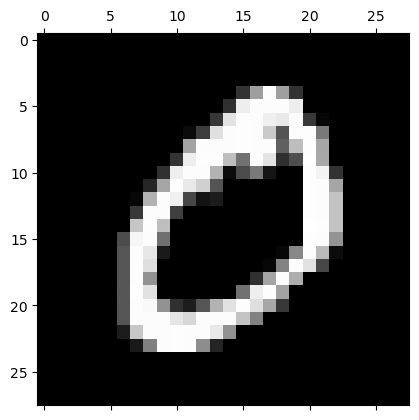

In [ ]:
plt.matshow(X_train[1],  cmap='gray') 

In [20]:
y_train[0:5]

array([5, 0, 4, 1, 9], dtype=uint8)

In [25]:
# flatten X_Train and X_test
# first len(X_train) gives us the number of images in the training set, and 28*28 gives us the number of pixels in each image
total_X_train = len(X_train)
total_columns = len(X_train[0]) * len(X_train[0][0]) # rows * columns = 28 * 28

total_X_test = len(X_test)

X_train_flattened = X_train.reshape(total_X_train, total_columns) # total columns = 28 * 28 = 784
X_test_flattened = X_test.reshape(total_X_test, total_columns)

In [26]:
X_train_flattened.shape

(60000, 784)

In [ ]:
X_train_flattened[0] # 2d to 1d array

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 17

## Now Simple Neural Network with 2 layers

In [ ]:
X_train_flattened = X_train_flattened / 255.0 # normalize the pixel values to be between 0 and 1
X_test_flattened = X_test_flattened / 255.0 

# it means create a model with 10 output layers and input shape is 784 feature and use sigmoid activation function
# Dense means each 784 input_features are connected to each of the 10 output layers as shown in the image below
model = keras.Sequential([
    keras.layers.Dense(10, input_shape=(784,), activation="sigmoid")
])

model.compile(
    optimizer="adam", # allow u to reach to global minimum faster than gradient descent 
    loss="sparse_categorical_crossentropy", # loss function for multi class classification problems
    metrics=["accuracy"] # to evaluate the model performance
)

# epochs means how many times the model will see the entire training data
model.fit(X_train_flattened, y_train, epochs=5) # train the model for 5 epochs

Epoch 1/5


c:\Users\Navnath\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8788 - loss: 0.4669
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9148 - loss: 0.3038
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9202 - loss: 0.2835
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9243 - loss: 0.2730
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9263 - loss: 0.2667


![Image](simple-2-layer-neural-network.png)

In [31]:
model.evaluate(X_test_flattened, y_test) # evaluate the model on the test data

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9229 - loss: 0.2698


[0.26976433396339417, 0.9229000210762024]

In [32]:
y_predicted = model.predict(X_test_flattened) # predict the labels for the test data
y_predicted[0] # predicted probabilities for each class for the first test image

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 821us/step


array([2.4965938e-02, 4.2045147e-07, 6.0056280e-02, 9.6062046e-01,
       2.4293521e-03, 1.3776216e-01, 1.2634032e-06, 9.9976331e-01,
       7.2215237e-02, 6.6246498e-01], dtype=float32)

In [33]:
# above output gives probability of 10 output layers
np.argmax(y_predicted[0]) # gives the index of the output layer with the highest probability which is the predicted label for the first test image

np.int64(7)

In [38]:
y_predicted_labels = [np.argmax(i) for i in y_predicted] # get the predicted labels for all test images
confusion_matrix = trf.math.confusion_matrix(y_test, y_predicted_labels)
confusion_matrix

<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 965,    0,    2,    2,    0,    6,    2,    2,    1,    0],
       [   0, 1118,    3,    2,    0,    1,    4,    2,    5,    0],
       [   9,   12,  918,   23,    8,    3,   11,   10,   35,    3],
       [   2,    0,   15,  935,    1,   18,    1,   11,   19,    8],
       [   2,    3,    6,    2,  917,    0,    7,    4,    8,   33],
       [  11,    3,    4,   42,   10,  776,   10,    5,   25,    6],
       [  12,    3,    9,    1,    8,   21,  900,    2,    2,    0],
       [   2,   12,   23,    7,    7,    1,    0,  943,    1,   32],
       [   6,   12,    6,   35,    9,   34,    8,   10,  842,   12],
       [  11,    7,    1,   13,   29,    9,    0,   21,    3,  915]],
      dtype=int32)>

## Adding Hidden Layer

In [ ]:
# it means create a model with 100 hidden layers and input shape is 784 feature and use sigmoid activation function
# Dense means each 784 input_features are connected to each of the 10 output layers as shown in the image below
model = keras.Sequential([
    keras.layers.Dense(100, input_shape=(784,), activation="relu"), # relu activation function is used to introduce non-linearity in the model and it helps the model to learn complex patterns in the data
    keras.layers.Dense(10, activation="sigmoid") # output layer with 10 output layers and use sigmoid activation function
])

# Basically it looks like this:
"""
input layer (784) --> hidden layer (100) --> output layer (10)    
"""

model.compile(
    optimizer="adam", # allow u to reach to global minimum faster than gradient descent 
    loss="sparse_categorical_crossentropy", # loss function for multi class classification problems
    metrics=["accuracy"] # to evaluate the model performance
)

# epochs means how many times the model will see the entire training data
model.fit(X_train_flattened, y_train, epochs=5) # train the model for 5 epochs

c:\Users\Navnath\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9264 - loss: 0.2659
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9643 - loss: 0.1223
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9751 - loss: 0.0845
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9803 - loss: 0.0655
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9846 - loss: 0.0504


In [40]:
model.evaluate(X_test_flattened, y_test) # evaluate the model on the test data

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9734 - loss: 0.0870


[0.08700606226921082, 0.9733999967575073]

In [41]:
y_predicted = model.predict(X_test_flattened) # predict the labels for the test data
y_predicted_labels = [np.argmax(i) for i in y_predicted] # get the predicted labels for all test images
trf.math.confusion_matrix(y_test, np.argmax(y_predicted, axis=1)) # confusion matrix to evaluate the performance of the model

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 845us/step


<tf.Tensor: shape=(10, 10), dtype=int32, numpy=
array([[ 970,    0,    1,    1,    1,    0,    2,    2,    3,    0],
       [   0, 1119,    4,    0,    0,    0,    2,    0,   10,    0],
       [   3,    0, 1014,    0,    2,    0,    2,    4,    6,    1],
       [   0,    1,    7,  985,    0,    0,    0,    4,    6,    7],
       [   0,    0,    8,    0,  958,    0,    3,    3,    3,    7],
       [   5,    0,    0,   32,    1,  826,    4,    3,   15,    6],
       [   3,    3,    2,    1,    6,    1,  937,    0,    5,    0],
       [   0,    5,   14,    3,    0,    0,    0,  996,    5,    5],
       [   3,    0,    7,    6,    3,    0,    1,    3,  948,    3],
       [   0,    3,    0,    7,    7,    0,    1,    9,    1,  981]],
      dtype=int32)>